# `survivorship.ipynb`

This notebook does the survivorship analysis used in Figure 5 and supplemental information.

In [193]:
import numpy as np
import pandas as pd

# Stats packages
from scipy.stats import ecdf
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines import CoxPHFitter, WeibullAFTFitter

# Plotting
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Misc
import testis_model as tm
import os

In [194]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [195]:
filepath = os.path.join('..', 'model_simulations', 'all_clone_results.csv')
df = pd.read_csv(filepath)

df = df[df['n_transient'] > 1].copy()

exp_scenario = 'full_pipeline_trunc'
df['died_early'] = df['last_time'] != df['max_time']
df.head()

,scenario,fish,duplicate,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,n_transient,size,avg_freq_change,r_opt,l_max,lower,upper,l_null,died_early
0,r36_rp5_mimic,1,0,0,5.0,0.809322,20.0,5.0,20.0,0.767655,11,0.747753,0.002778,0.734669,-137.014545,0.231772,2.631180,-156.420841,False
1,r36_rp5_mimic,1,0,1,5.0,0.096751,20.0,5.0,20.0,0.031780,11,0.132576,0.004331,4.112847,-133.666750,1.773068,11.750108,-348.164613,False
2,r36_rp5_mimic,1,0,2,5.0,0.062147,20.0,5.0,20.0,0.200565,11,0.112224,-0.009228,2.283607,-126.116370,0.888735,6.989279,-289.429360,False
3,r36_rp5_mimic,1,0,3,5.0,0.021186,10.0,5.0,20.0,0.000000,4,0.004494,0.004096,2.399909,-35.368118,0.704391,9.402862,-125.333891,True
4,r36_rp5_mimic,1,0,4,5.0,0.010593,11.0,5.0,20.0,0.000000,5,0.002953,0.001412,2.053634,-38.379028,0.551991,6.869552,-78.825582,True


## Visualize survivorship

Text(0, 0.5, 'Count')

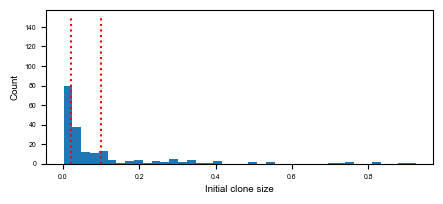

In [196]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == @exp_scenario')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.set_xlabel('Initial clone size')
ax.set_ylabel('Count')

In [197]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of experimental clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

36.0% of experimental clones have a size below 0.02, 35.5% have a size between 0.02 and 0.10, and 28.5% of clones have a size above 0.10.


In [198]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] >= large_cutoff, 'tertile'] = 'large'

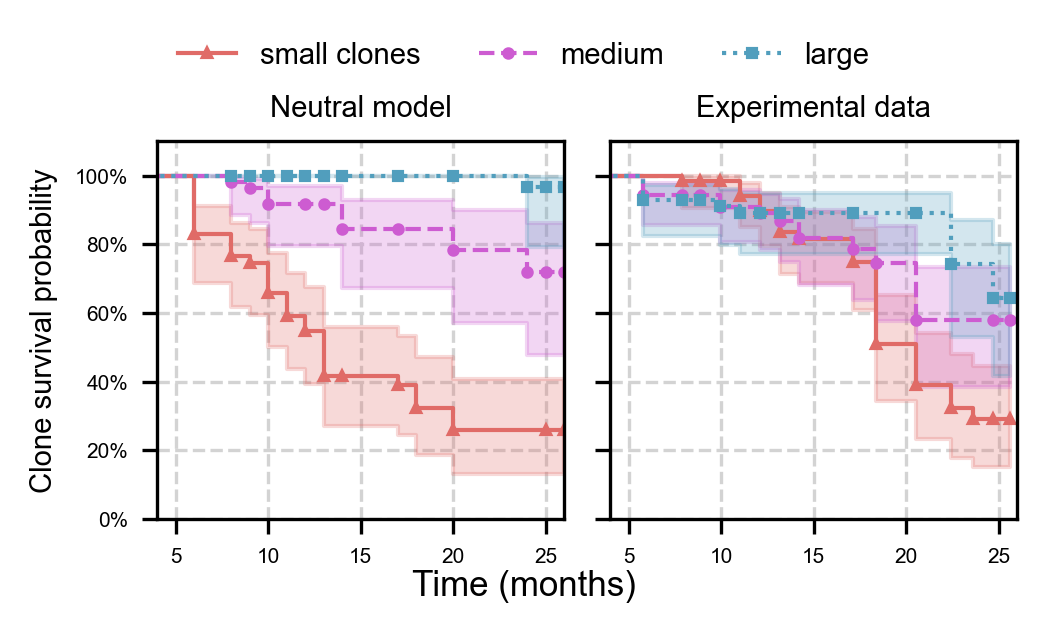

In [199]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(1, 2, figsize=(3.5, 2), dpi=300, sharey=True)

n_experimental_fish = 24
compare_scenario = 'r36_rp2_mimic'

# Tertile definitions and plotting styles
tertiles = {
    "small":  dict(color="#e06b67", marker="^", linestyle="-",  label="small clones"),
    "medium": dict(color="#cd5cd1", marker="o", linestyle="--", label="medium"),
    "large":  dict(color="#519ebd", marker="s", linestyle=":",  label="large"),
}

def subset_data(df, scenario, tertile):
    """Return the appropriate subset for a given scenario and tertile."""
    base = df.query("scenario == @scenario and tertile == @tertile")
    if scenario == exp_scenario:
        return base
    return base.query("duplicate == 0")

def plot_km(ax, data, style):
    """Fit and plot a Kaplan–Meier curve with consistent styling."""
    km = KaplanMeierFitter()
    km.fit(durations=data["last_time"], event_observed=data["died_early"])
    km.plot_survival_function(
        ax=ax,
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        markersize=2,
        linewidth=1,
        label=style["label"],
    )

for i, scenario in enumerate([compare_scenario, exp_scenario]):
    axis = ax[i]

    for tertile, style in tertiles.items():
        data = subset_data(df, scenario, tertile)
        plot_km(axis, data, style)

    axis.set_xlabel("")
    axis.grid(True, linestyle="--", linewidth=0.8, color="lightgray")
    axis.set_axisbelow(True)
    axis.set_xticks([5, 10, 15, 20, 25])
    axis.set_xlim([4, 26])
    axis.set_ylim([0, 1.1])
    axis.set_title("Neutral model" if i == 0 else "Experimental data")
    axis.legend_.remove()

ax[0].set_ylabel("Clone survival probability")
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)
fig.supxlabel("Time (months)", y=0.1)

plt.tight_layout()
plt.savefig(os.path.join("images", "survivorship_tertile.svg"),
            transparent=True, bbox_inches="tight")

## Cox PH Model

In [84]:
# We will compare the experimental data to the rp=2 model, since that matches
# the median rp estimate.
df[df['scenario'] == 'full_pipeline']['r_opt'].median()

2.0177610158110704

In [165]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

df2 = df.query(
    "scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == 0)"
).copy()
df2['scenario'] = pd.Categorical(df2['scenario'])
df2['scenario'] = df2['scenario'].cat.reorder_categories(
    [exp_scenario, sim_scenario]
)

df2.groupby('scenario', observed=False).agg({'died_early': 'mean'})
# Slightly more of the simulations died early in this comparison.

,died_early
scenario,
full_pipeline,0.342960
r36_rp2_mimic,0.229885


In [166]:
# Fit to Cox PH model.
cph = CoxPHFitter()
cph.fit(df2, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 451 total observations, 316 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 451
number of events observed = 135
   partial log-likelihood = -694.04
         time fit was run = 2025-12-23 16:39:35 UTC

---
                                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                             
init_freq                            -1.72      0.18      0.88           -3.45            0.02                0.03                1.02
scenario[T.r36_rp2_mimic]             1.11      3.03      0.24            0.64            1.58                1.89                4.87
init_freq:scenario[T.r36_rp2_mimic] -32.93      0.00      7.21          -47.06          -18.81                0.00                0.00

                                     cmp to     z      p  -log2(p)
covariate                                                         
init_freq                              0.00 -1.94   0.05      4.26
scenario[T.r36_rp2_mimic]              0.00  4.59 <0.005     17.79
init_freq:scenario[T.r36_rp2_mimic]    0.00 -4.57 <0.005     17.65
---
Concordance = 0.72
Partial AIC = 1394.09
log-likelihood ratio test = 85.36 on 3 df
-log2(p) of ll-ratio test = 58.67

In [167]:
# The model data does not pass PH test.
results = proportional_hazard_test(cph, df2, time_transform='rank')
print(results.summary)

                                     test_statistic         p   -log2(p)
init_freq                                  4.394485  0.036055   4.793643
init_freq:scenario[T.r36_rp2_mimic]       11.069515  0.000878  10.154171
scenario[T.r36_rp2_mimic]                 19.802936  0.000009  16.829738


## Weibull Model

In [210]:
def fit_weibull(df, exp_scenario, sim_scenario, duplicate):
    df2 = df.query(
        "scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == @duplicate)"
    ).copy()
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [exp_scenario, sim_scenario]
    )

    aft = WeibullAFTFitter()
    aft.fit(df2, duration_col="last_time", event_col="died_early", formula="init_freq * scenario")
    return aft, df2

In [219]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

aft, df2 = fit_weibull(df, exp_scenario, sim_scenario, 0)
aft.print_summary()

<lifelines.WeibullAFTFitter: fitted with 451 total observations, 316 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
   number of observations = 451
number of events observed = 135
           log-likelihood = -583.58
         time fit was run = 2025-12-23 17:57:14 UTC

---
                                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                            
lambda_ Intercept                            3.26     26.00      0.05            3.15            3.36               23.40               28.89
        init_freq                            0.75      2.12      0.38            0.01            1.49                1.01                4.43
        scenario[T.r36_rp2_mimic]           -0.44      0.64      0.11           -0.65           -0.24                0.52                0.79
        init_freq:scenario[T.r36_rp2_mimic] 13.95  1.14e+06      3.19            7.70           20.19             2215.44            5.86e+08
rho_    Intercept                            0.86      2.36      0.07            0.73            1.00                2.07                2.71

                                             cmp to     z      p  -log2(p)
param   covariate                                                         
lambda_ Intercept                              0.00 60.54 <0.005       inf
        init_freq                              0.00  1.99   0.05      4.43
        scenario[T.r36_rp2_mimic]              0.00 -4.20 <0.005     15.18
        init_freq:scenario[T.r36_rp2_mimic]    0.00  4.38 <0.005     16.35
rho_    Intercept                              0.00 12.54 <0.005    117.36
---
Concordance = 0.72
AIC = 1177.15
log-likelihood ratio test = 88.39 on 3 df
-log2(p) of ll-ratio test = 60.84

In [220]:
p_initfreq = aft.summary['p'].loc['lambda_', 'init_freq']
p_interact = aft.summary['p'].loc['lambda_', f'init_freq:scenario[T.{sim_scenario}]']

print(f'The p value of initial frequency dependence in the experimental data is {p_initfreq:.2e}. \
The p value of interaction is {p_interact:.2e}.')

The p value of initial frequency dependence in the experimental data is 4.65e-02. The p value of interaction is 1.20e-05.


## Repeat statistical test over multiple simulation runs

The purpose of this section is to make sure our first test was not "lucky."
You can set `exp_scenario` to `full_pipeline`, `full_pipeline_trunc`, or `no_collapse`.

In [229]:
rs = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6]
rows = []

exp_scenario = 'full_pipeline'

for r in rs:
    compare_scenario = f'r36_rp{r}_mimic'

    for d in df['duplicate'].unique():
        aft, df2 = fit_weibull(df, exp_scenario, compare_scenario, d)
        summary = aft.summary
    
        intercept = summary.loc[('lambda_', 'Intercept')]
        init_freq = summary.loc[('lambda_', 'init_freq')]
        interact = summary.loc[('lambda_', f'scenario[T.{compare_scenario}]')]
        interact_init_freq = summary.loc[('lambda_', f'init_freq:scenario[T.{compare_scenario}]')]
        
        row = {'r': r, 'duplicate': d, 'intercept': intercept.p, 'init. freq.': init_freq.p,
              'interact': interact.p, 'interact init_freq': interact_init_freq.p}
    
        overall_survive = df2.query('scenario == @compare_scenario')['died_early'].mean() * 100
        row['overall_survive'] = f'{overall_survive:.0f}%'
        rows.append(row)

# Build DataFrame
results_df = pd.DataFrame(rows)
results_df.set_index("r", inplace=True)

In [230]:
not_sig = results_df[results_df['interact init_freq'] > 0.05]
print(f'There was {len(not_sig)} non-significant init_freq interaction out of {len(results_df)} total tests. \
The not significant result(s) are below:')

not_sig

There was 1 non-significant init_freq interaction out of 90 total tests. The not significant result(s) are below:


,duplicate,intercept,init. freq.,interact,interact init_freq,overall_survive
r,,,,,,
5.0,6,0.0,0.046932,0.311126,0.087367,25%
